#Training the models

In [2]:
import numpy as np

np.random.seed(42)
m = 100
X = 2 * np.random.rand(m, 1)

y = 4 + 3 * X + np.random.randn(m , 1)


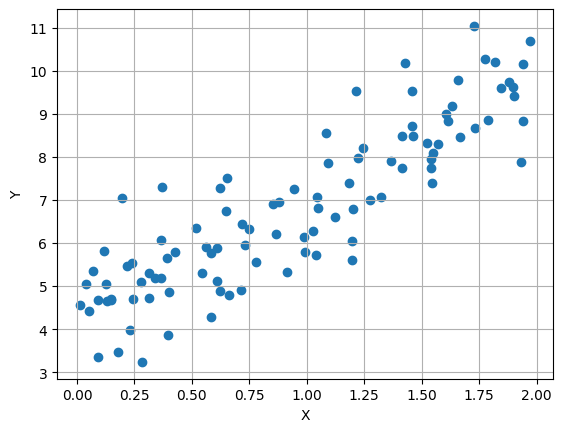

In [3]:
import matplotlib.pyplot as plt

plt.scatter(X, y)
plt.grid()
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

In [4]:
X

array([[0.74908024],
       [1.90142861],
       [1.46398788],
       [1.19731697],
       [0.31203728],
       [0.31198904],
       [0.11616722],
       [1.73235229],
       [1.20223002],
       [1.41614516],
       [0.04116899],
       [1.9398197 ],
       [1.66488528],
       [0.42467822],
       [0.36364993],
       [0.36680902],
       [0.60848449],
       [1.04951286],
       [0.86389004],
       [0.58245828],
       [1.22370579],
       [0.27898772],
       [0.5842893 ],
       [0.73272369],
       [0.91213997],
       [1.57035192],
       [0.39934756],
       [1.02846888],
       [1.18482914],
       [0.09290083],
       [1.2150897 ],
       [0.34104825],
       [0.13010319],
       [1.89777107],
       [1.93126407],
       [1.6167947 ],
       [0.60922754],
       [0.19534423],
       [1.36846605],
       [0.88030499],
       [0.24407647],
       [0.99035382],
       [0.06877704],
       [1.8186408 ],
       [0.51755996],
       [1.32504457],
       [0.62342215],
       [1.040

In [5]:
y

array([[ 6.33428778],
       [ 9.40527849],
       [ 8.48372443],
       [ 5.60438199],
       [ 4.71643995],
       [ 5.29307969],
       [ 5.82639572],
       [ 8.67878666],
       [ 6.79819647],
       [ 7.74667842],
       [ 5.03890908],
       [10.14821022],
       [ 8.46489564],
       [ 5.7873021 ],
       [ 5.18802735],
       [ 6.06907205],
       [ 5.12340036],
       [ 6.82087644],
       [ 6.19956196],
       [ 4.28385989],
       [ 7.96723765],
       [ 5.09801844],
       [ 5.75798135],
       [ 5.96358393],
       [ 5.32104916],
       [ 8.29041045],
       [ 4.85532818],
       [ 6.28312936],
       [ 7.3932017 ],
       [ 4.68275333],
       [ 9.53145501],
       [ 5.19772255],
       [ 4.64785995],
       [ 9.61886731],
       [ 7.87502098],
       [ 8.82387021],
       [ 5.88791282],
       [ 7.0492748 ],
       [ 7.91303719],
       [ 6.9424623 ],
       [ 4.69751764],
       [ 5.80238342],
       [ 5.34915394],
       [10.20785545],
       [ 6.34371184],
       [ 7

#Linear Regression

In [6]:
from sklearn.preprocessing import add_dummy_feature

X_b = add_dummy_feature(X)

thetha_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

In [7]:
print(thetha_best)

[[4.21509616]
 [2.77011339]]


In [8]:
thetha_best_pinv = np.linalg.pinv(X_b) @ y 
print(thetha_best_pinv)

[[4.21509616]
 [2.77011339]]


In [9]:
X_new = np.array([[0], [2]])
x_new_b = add_dummy_feature(X_new)
y_predict = x_new_b @ thetha_best
y_predict

array([[4.21509616],
       [9.75532293]])

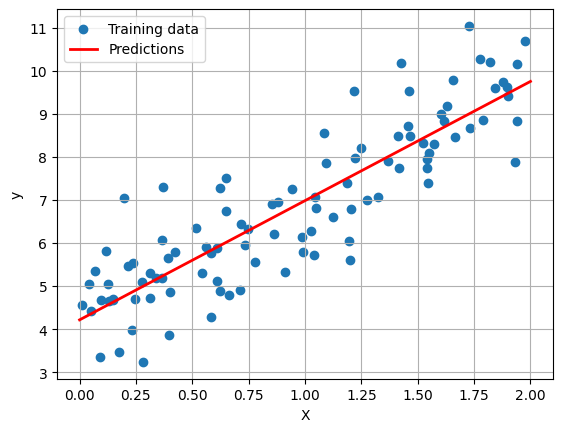

In [10]:
import matplotlib.pyplot as plt

plt.scatter(X, y, label="Training data")

plt.plot(X_new, y_predict, "r-", linewidth=2, label="Predictions")

plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.grid()
plt.show()

In [11]:
from sklearn.linear_model import LinearRegression 
lin_reg = LinearRegression()
lin_reg.fit(X, y)
lin_reg.intercept_, lin_reg.coef_

(array([4.21509616]), array([[2.77011339]]))

In [12]:
lin_reg

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [13]:
np.linalg.pinv(X_b) @ y

array([[4.21509616],
       [2.77011339]])

#Gradient Descent

In [14]:
eta = 0.1
n_epochs = 1000
m = len(X_b)

np.random.seed(42)
theta = np.random.randn(2, 1)

for epoch in range(n_epochs):
    gradients = 2 / m * X_b.T @ (X_b @ theta - y)
    theta = theta - eta * gradients


In [15]:
theta

array([[4.21509616],
       [2.77011339]])

In [16]:
eta = 0.02
n_epochs = 1000
m = len(X_b)

np.random.seed(42)
theta = np.random.randn(2, 1)

for epoch in range(n_epochs):
    gradients = 2 / m * X_b.T @ (X_b @ theta - y)
    theta = theta - eta * gradients


In [17]:
theta

array([[4.21438446],
       [2.77074177]])

In [18]:
eta = 0.5
n_epochs = 1000
m = len(X_b)

np.random.seed(42)
theta = np.random.randn(2, 1)

for epoch in range(n_epochs):
    gradients = 2 / m * X_b.T @ (X_b @ theta - y)
    theta = theta - eta * gradients


In [19]:
theta

array([[-7.05138935e+27],
       [-7.98621001e+27]])

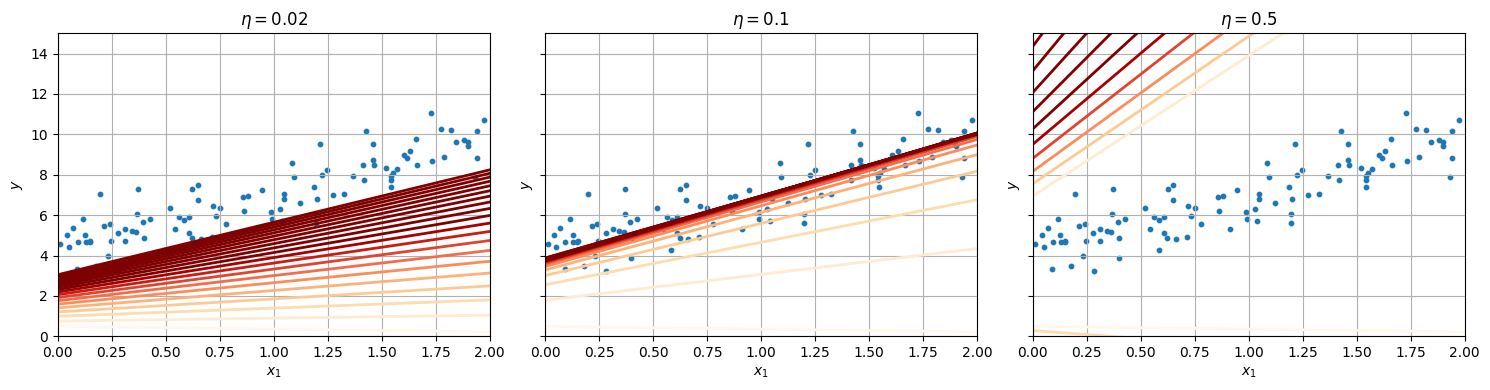

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import add_dummy_feature


np.random.seed(42)
m = 100
X = 2 * np.random.rand(m, 1)
y = 4 + 3 * X + np.random.randn(m, 1)

X_b = add_dummy_feature(X)   
X_new = np.array([[0], [2]])
X_new_b = add_dummy_feature(X_new)


def plot_gradient_descent(theta, eta, ax, n_epochs=20):
    ax.scatter(X, y, s=10)  

    for epoch in range(n_epochs):
       
        y_predict = X_new_b @ theta

        if epoch < 20:
            ax.plot(X_new, y_predict, color=plt.cm.OrRd(epoch / 10), linewidth=2)

        
        gradients = 2 / m * X_b.T @ (X_b @ theta - y)

        
        theta = theta - eta * gradients

    ax.set_title(r"$\eta = {}$".format(eta))
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$y$")
    ax.set_xlim(0, 2)
    ax.set_ylim(0, 15)
    ax.grid(True)


np.random.seed(42)
theta_initial = np.random.randn(2, 1)

fig, axes = plt.subplots(ncols=3, figsize=(15, 4), sharey=True)

plot_gradient_descent(theta_initial.copy(), eta=0.02, ax=axes[0])
plot_gradient_descent(theta_initial.copy(), eta=0.1, ax=axes[1])
plot_gradient_descent(theta_initial.copy(), eta=0.5, ax=axes[2])

plt.tight_layout()
plt.show()

#Stocastic Gradient Descent

In [21]:
n_epochs = 50 
t0, t1 = 5, 50

def learning_schedule(t):
    return t0 / (t + t1) 

np.random.seed(42)
theta = np.random.randn(2, 1)

for epoch in range(n_epochs):
    for iteration in range(m):
        random_index = np.random.randint(m)
        xi = X_b[random_index : random_index + 1]
        yi = y[random_index : random_index + 1]
        gradients = 2 * xi.T @ (xi @ theta - yi)
        eta = learning_schedule(epoch * m + iteration)
        theta = theta - eta * gradients


In [22]:
theta 

array([[4.21076011],
       [2.74856079]])

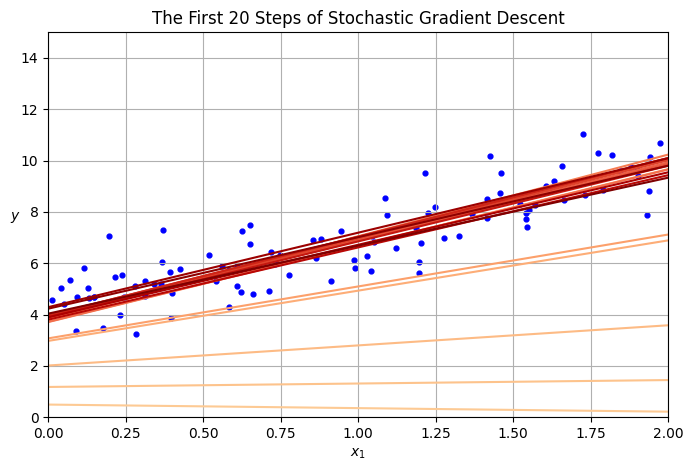

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import add_dummy_feature


np.random.seed(42)
m = 100

X = 2 * np.random.rand(m, 1)
y = 4 + 3 * X + np.random.randn(m, 1)

X_b = add_dummy_feature(X)


X_new = np.array([[0], [2]])
X_new_b = add_dummy_feature(X_new)


n_epochs = 50
t0, t1 = 5, 50

def learning_schedule(t):
    return t0 / (t + t1)


np.random.seed(42)
theta = np.random.randn(2, 1)


fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(X, y, color="blue", s=12)

for epoch in range(n_epochs):
    for iteration in range(m):

        if epoch == 0 and iteration < 20:

            y_predict = X_new_b @ theta

            color = plt.cm.OrRd(0.3 + 0.7 * iteration / 19)

            ax.plot(
                X_new,
                y_predict,
                color=color,
                linewidth=1.5
            )

        random_index = np.random.randint(m)

        xi = X_b[random_index:random_index + 1]
        yi = y[random_index:random_index + 1]

        gradients = 2 * xi.T @ (xi @ theta - yi)

        eta = learning_schedule(epoch * m + iteration)

  
        theta = theta - eta * gradients

ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$y$", rotation=0)
ax.set_xlim(0, 2)
ax.set_ylim(0, 15)
ax.set_title("The First 20 Steps of Stochastic Gradient Descent")
ax.grid(True)

plt.show()

In [24]:
from sklearn.linear_model import SGDRegressor

sgd_regressor = SGDRegressor(max_iter=100, tol=1e-5, penalty=None, eta0=0.01, n_iter_no_change=100,random_state=42)

sgd_regressor.fit(X, y.ravel())

/home/chintu/miniconda3/envs/ml-basics/lib/python3.11/site-packages/sklearn/linear_model/_stochastic_gradient.py:1612: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


,"loss loss: str, default='squared_error'The loss function to be used. The possible values are 'squared_error','huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'The 'squared_error' refers to the ordinary least squares fit.'huber' modifies 'squared_error' to focus less on getting outlierscorrect by switching from squared to linear loss past a distance ofepsilon. 'epsilon_insensitive' ignores errors less than epsilon and islinear past that; this is the loss function used in SVR.'squared_epsilon_insensitive' is the same but becomes squared loss pasta tolerance of epsilon.More details about the losses formulas can be found in the:ref:`User Guide `.",'squared_error'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",None
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",100
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",1e-05
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only if `loss` is'huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'.For 'huber', determines the threshold at which it becomes lessimportant to get the prediction exactly right.For epsilon-insensitive, any differences between the current predictionand the correct label are ignored if they are less than this threshold.Values must be in the range `[0.0, inf)`.",0.1
,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",42


In [25]:
print("Intercept : ", sgd_regressor.intercept_)
print("Coefficients : ", sgd_regressor.coef_)

print("Actual epochs : ", sgd_regressor.n_iter_)
print("Update counter : ", sgd_regressor.t_)


print("preictions : ", sgd_regressor.predict(X_new) )

Intercept :  [4.11071407]
Coefficients :  [2.86451566]
Actual epochs :  100
Update counter :  10001.0
preictions :  [4.11071407 9.8397454 ]


#Polynomial Regression

In [26]:
np.random.seed(42)
m = 100
X = 6 * np.random.rand(m, 1) - 3
y =0.5 * X ** 2 + X + 2 + np.random.randn(m, 1)


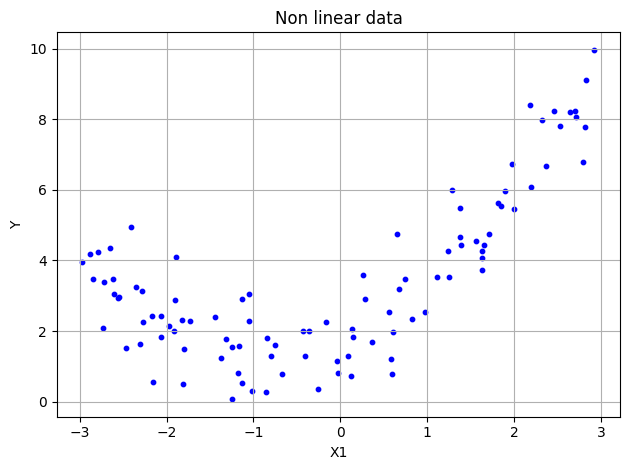

In [27]:
plt.scatter(X, y, color="blue",s=10)
plt.title("Non linear data")
plt.xlabel("X1")
plt.ylabel("Y")
plt.grid()
plt.tight_layout()
plt.show()

In [28]:
from sklearn.preprocessing import PolynomialFeatures
poly_features = PolynomialFeatures(degree=2, include_bias=False)

X_poly = poly_features.fit_transform(X)
X[0]



array([-0.75275929])

In [29]:
X_poly[0]

array([-0.75275929,  0.56664654])

In [30]:
lin_reg = LinearRegression()
lin_reg.fit(X_poly, y)
lin_reg.intercept_, lin_reg.coef_

(array([1.78134581]), array([[0.93366893, 0.56456263]]))

In [31]:
X_new_poly = poly_features.transform(X_new)
y_new = lin_reg.predict(X_new_poly)

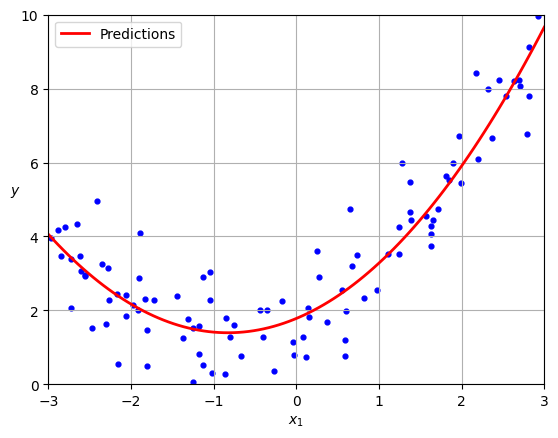

In [32]:
import numpy as np
import matplotlib.pyplot as plt

X_new = np.linspace(-3, 3, 100).reshape(-1, 1)

X_new_poly = poly_features.transform(X_new)

y_new = lin_reg.predict(X_new_poly)

plt.scatter(X, y, color="blue", s=12)

plt.plot(X_new, y_new, "r-", linewidth=2, label="Predictions")

plt.xlabel(r"$x_1$")
plt.ylabel(r"$y$", rotation=0)
plt.xlim(-3, 3)
plt.ylim(0, 10)
plt.legend(loc="upper left")
plt.grid(True)

plt.show()

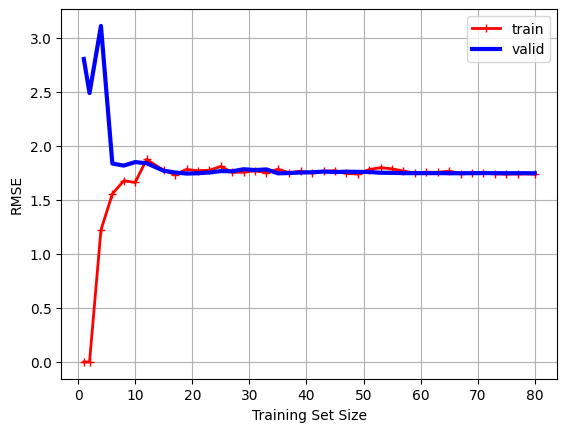

In [33]:
from sklearn.model_selection import learning_curve 

train_size, train_scores, valid_scores = learning_curve(
    LinearRegression(), X, y, train_sizes=np.linspace(0.01, 1.0, 40), cv=5, scoring="neg_root_mean_squared_error")

train_errors = -train_scores.mean(axis=1)
valid_errors = -valid_scores.mean(axis=1)

plt.plot(train_size, train_errors,"r-+", linewidth=2, label="train" )
plt.plot(train_size, valid_errors,"b-", linewidth=3,label="valid")
plt.xlabel("Training Set Size")
plt.ylabel("RMSE")
plt.grid(True)
plt.legend()
plt.show() 

In [34]:
train_scores

array([[-0.00000000e+00, -0.00000000e+00, -0.00000000e+00,
        -0.00000000e+00, -0.00000000e+00],
       [-4.44089210e-16, -3.14018492e-16, -3.14018492e-16,
        -3.14018492e-16, -3.14018492e-16],
       [-6.74202452e-01, -1.35541971e+00, -1.35541971e+00,
        -1.35541971e+00, -1.35541971e+00],
       [-1.12165340e+00, -1.66264469e+00, -1.66264469e+00,
        -1.66264469e+00, -1.66264469e+00],
       [-1.06106104e+00, -1.82896912e+00, -1.82896912e+00,
        -1.82896912e+00, -1.82896912e+00],
       [-1.17284592e+00, -1.78232603e+00, -1.78232603e+00,
        -1.78232603e+00, -1.78232603e+00],
       [-1.21773577e+00, -2.03615199e+00, -2.03615199e+00,
        -2.03615199e+00, -2.03615199e+00],
       [-1.54482890e+00, -1.82873013e+00, -1.82873013e+00,
        -1.82873013e+00, -1.82873013e+00],
       [-1.47246146e+00, -1.79805676e+00, -1.79805676e+00,
        -1.79805676e+00, -1.79805676e+00],
       [-1.60541806e+00, -1.82355971e+00, -1.82355971e+00,
        -1.82355971e+00

In [35]:
valid_scores

array([[-2.36452507, -2.56711283, -3.314824  , -2.97448171, -2.78963255],
       [-2.12424827, -2.63795855, -2.73836243, -2.40638514, -2.52612012],
       [-2.24768665, -3.38468313, -3.52295015, -3.21137327, -3.17221406],
       [-2.08744135, -1.70148586, -1.90960018, -1.6399481 , -1.83534705],
       [-2.17835195, -1.62096626, -1.80870297, -1.66835092, -1.80291772],
       [-2.2905765 , -1.58871859, -1.88234967, -1.69665652, -1.7828119 ],
       [-2.1246079 , -1.67393841, -1.81810739, -1.7211748 , -1.8505214 ],
       [-1.86155114, -1.65425749, -1.80434756, -1.68849295, -1.83168328],
       [-1.8638321 , -1.63037146, -1.79838675, -1.65888628, -1.80909469],
       [-1.87177026, -1.59682799, -1.82062495, -1.64128491, -1.77988038],
       [-1.87307251, -1.59525437, -1.84576391, -1.63518384, -1.77703725],
       [-1.90651726, -1.58821386, -1.84934809, -1.63883422, -1.77694417],
       [-1.87555049, -1.60173089, -1.897251  , -1.6604848 , -1.79014693],
       [-1.87789589, -1.59310933, -1.8

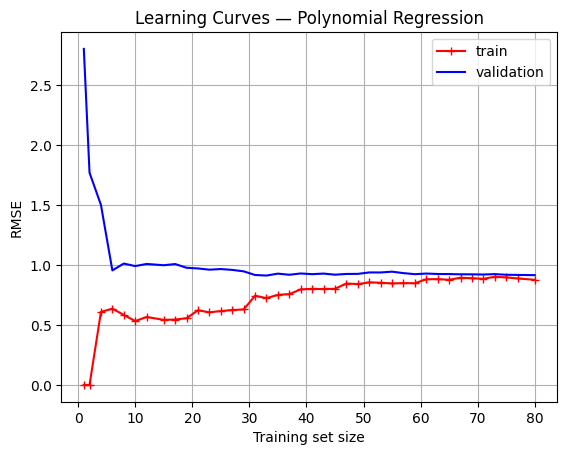

In [36]:
from sklearn.pipeline import make_pipeline 

from sklearn.preprocessing import PolynomialFeatures 

poly_reg = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

poly_train_sizes, poly_train_scores, poly_valid_scores = learning_curve(
    poly_reg, X, y, train_sizes=np.linspace(0.01, 1.0, 40), cv=5, scoring="neg_root_mean_squared_error"
)

poly_train_errors = -poly_train_scores.mean(axis=1)
poly_valid_errors = -poly_valid_scores.mean(axis=1)

plt.plot(poly_train_sizes, poly_train_errors, "r-+", label="train")
plt.plot(poly_train_sizes, poly_valid_errors, "b-", label="validation")

plt.xlabel("Training set size")
plt.ylabel("RMSE")
plt.title("Learning Curves — Polynomial Regression")
plt.legend()
plt.grid(True)
plt.show()

In [37]:
poly_train_errors

array([-0.00000000e+00,  1.42404278e-15,  6.08912867e-01,  6.36069811e-01,
        5.83572544e-01,  5.32612071e-01,  5.66379088e-01,  5.42566529e-01,
        5.45289072e-01,  5.56364091e-01,  6.22343529e-01,  6.05393678e-01,
        6.16010984e-01,  6.24530596e-01,  6.29352914e-01,  7.43386305e-01,
        7.23652915e-01,  7.51342913e-01,  7.57176622e-01,  7.96868904e-01,
        8.01000593e-01,  7.99872167e-01,  8.01699543e-01,  8.45787065e-01,
        8.41046543e-01,  8.54869573e-01,  8.52389864e-01,  8.46303065e-01,
        8.49319986e-01,  8.47912762e-01,  8.81230424e-01,  8.82556808e-01,
        8.77025748e-01,  8.93841883e-01,  8.89719198e-01,  8.84606018e-01,
        9.02105695e-01,  8.96529260e-01,  8.87949873e-01,  8.76569756e-01])

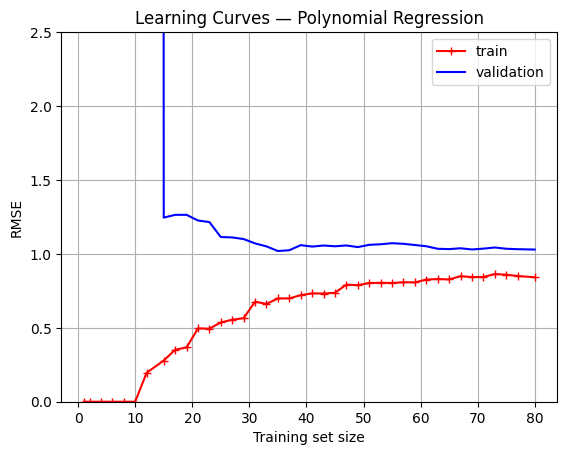

In [38]:
from sklearn.pipeline import make_pipeline 

from sklearn.preprocessing import PolynomialFeatures 

poly_reg = make_pipeline(
    PolynomialFeatures(degree=10, include_bias=False),
    LinearRegression()
)

poly_train_sizes, poly_train_scores, poly_valid_scores = learning_curve(
    poly_reg, X, y, train_sizes=np.linspace(0.01, 1.0, 40), cv=5, scoring="neg_root_mean_squared_error"
)

poly_train_errors = -poly_train_scores.mean(axis=1)
poly_valid_errors = -poly_valid_scores.mean(axis=1)

plt.plot(poly_train_sizes, poly_train_errors, "r-+", label="train")
plt.plot(poly_train_sizes, poly_valid_errors, "b-", label="validation")

plt.xlabel("Training set size")
plt.ylabel("RMSE")
plt.title("Learning Curves — Polynomial Regression")
plt.legend()
plt.ylim(0, 2.5)
plt.grid(True)
plt.show()

#Ridge Regression (Tikhonov regularization)

In [39]:
from sklearn.linear_model import Ridge 

ridge_reg = Ridge(alpha=0.1, solver="cholesky")

ridge_reg.fit(X, y)

ridge_reg.predict([[1.5]])

array([4.82899748])

In [41]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge

ridge_poly = make_pipeline(
    PolynomialFeatures(degree=10, include_bias=False),
    StandardScaler(),
    Ridge(alpha=0.1)
)

ridge_poly.fit(X, y.ravel())

print(ridge_poly.predict([[1.5]]))

[4.60445304]


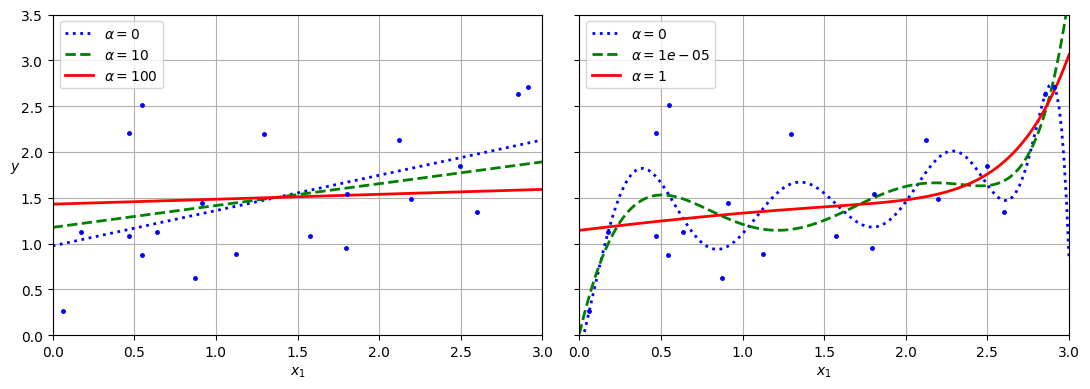

In [42]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import Ridge, LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline

np.random.seed(42)

m = 20
X = 3 * np.random.rand(m, 1)
y = 1 + 0.5 * X + np.random.randn(m, 1) / 1.5

X_new = np.linspace(0, 3, 200).reshape(-1, 1)


def plot_ridge_model(ax, alphas, polynomial=False):

    for alpha, style in zip(alphas, ("b:", "g--", "r-")):

        if alpha == 0:
            model = LinearRegression()
        else:
            model = Ridge(alpha=alpha, solver="cholesky")

        if polynomial:
            model = make_pipeline(
                PolynomialFeatures(degree=10, include_bias=False),
                StandardScaler(),
                model
            )

        model.fit(X, y)
        y_predict = model.predict(X_new)

        ax.plot(
            X_new,
            y_predict,
            style,
            linewidth=2,
            label=fr"$\alpha = {alpha:g}$"
        )

    ax.plot(X, y, "b.", markersize=5)
    ax.set_xlim(0, 3)
    ax.set_ylim(0, 3.5)
    ax.set_xlabel(r"$x_1$")
    ax.grid(True)
    ax.legend(loc="upper left")


fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)


plot_ridge_model(
    axes[0],
    alphas=(0, 10, 100),
    polynomial=False
)

axes[0].set_ylabel(r"$y$", rotation=0)


plot_ridge_model(
    axes[1],
    alphas=(0, 1e-5, 1),
    polynomial=True
)

plt.tight_layout()
plt.show()

In [43]:
sgd_reg = SGDRegressor(penalty="l2", alpha=0.1 /m, tol=None, max_iter=1000, eta0=0.01, random_state=42)

sgd_reg.fit(X, y.ravel())
sgd_reg.predict([[1.5]])

array([1.55302613])

#Lasso Regression(Least absolute shrinkage  and selection operator regression)

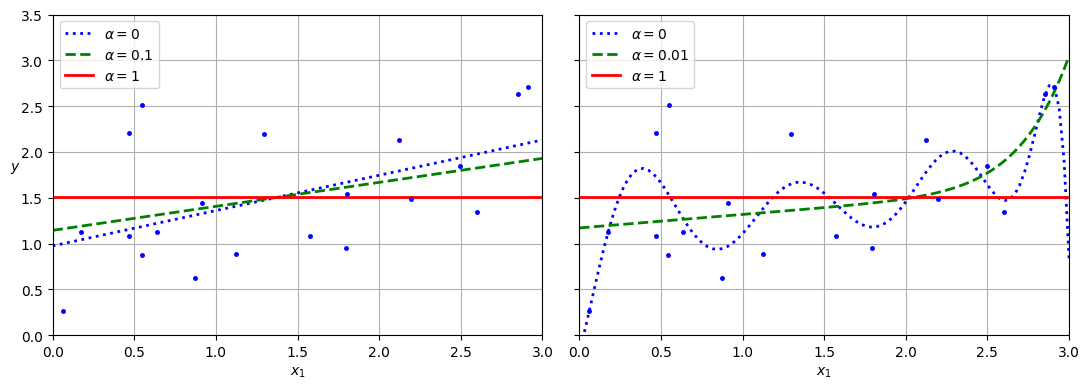

In [44]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import Lasso, LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline

np.random.seed(42)

m = 20
X = 3 * np.random.rand(m, 1)
y = 1 + 0.5 * X + np.random.randn(m, 1) / 1.5


X_new = np.linspace(0, 3, 100).reshape(-1, 1)


def plot_lasso_model(ax, alphas, polynomial=False):

    for alpha, style in zip(alphas, ("b:", "g--", "r-")):

        if alpha == 0:
            model = LinearRegression()
        else:
            model = Lasso(alpha=alpha, max_iter=100000)

        if polynomial:
            model = make_pipeline(
                PolynomialFeatures(degree=10, include_bias=False),
                StandardScaler(),
                model
            )

        model.fit(X, y.ravel())

        y_predict = model.predict(X_new)

        ax.plot(
            X_new,
            y_predict,
            style,
            linewidth=2,
            label=fr"$\alpha = {alpha:g}$"
        )

    ax.plot(X, y, "b.", markersize=5)

    ax.set_xlim(0, 3)
    ax.set_ylim(0, 3.5)
    ax.set_xlabel(r"$x_1$")
    ax.grid(True)
    ax.legend(loc="upper left")


fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

plot_lasso_model(
    axes[0],
    alphas=(0, 0.1, 1),
    polynomial=False
)

axes[0].set_ylabel(r"$y$", rotation=0)


plot_lasso_model(
    axes[1],
    alphas=(0, 0.01, 1),
    polynomial=True
)

plt.tight_layout()
plt.show()